# Bài 1 – Xây dựng MLP – PyTorch

Bám theo mã giảng viên: **800 mẫu make_moons, noise=0.25, 20 epoch**,
train/validation **640/160**, batch train 32, seed 42.
Đề tham chiếu: `../Buoi1/bai1.txt`.

Chọn kernel Python của `Buoi1_PyTorch/.venv`, rồi **Run All**. Kết quả đã lưu sẵn trong notebook.
`common.py` mới phải nằm cùng thư mục. Các cấu hình giữ đúng như script cùng tên.

## 1. Thư viện và tham số

MLP nhận hai tọa độ, qua các tầng ẩn rồi xuất hai logits cho hai lớp.
CrossEntropyLoss đo sai số; Adam cập nhật trọng số qua lan truyền ngược.
Một epoch là một lượt học qua toàn bộ train. Giữ số epoch theo mã mẫu.

In [1]:
from pathlib import Path
from dataclasses import asdict
from time import perf_counter
import sys
import itertools

cwd = Path.cwd().resolve()
paths = [cwd, cwd / "Buoi1_PyTorch", *[p / "Buoi1_PyTorch" for p in cwd.parents]]
BASE = next((p for p in paths if (p / "common.py").is_file() and p.name == "Buoi1_PyTorch"), None)
if BASE is None:
    raise FileNotFoundError("Mở notebook từ repository DeepL hoặc thư mục Buoi1_PyTorch.")
sys.path.insert(0, str(BASE))
# Tránh dùng nhầm common.py của bản cũ khi trước đó mở notebook khác.
if "common" in sys.modules and Path(sys.modules["common"].__file__).resolve() != BASE / "common.py":
    del sys.modules["common"]

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, random_split
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from IPython.display import display, Markdown, Image
from common import Config, seed_everything, build_mlp, evaluate, save_results

%matplotlib inline
print("PyTorch:", torch.__version__)

PyTorch: 2.14.1+cpu


In [2]:
EPOCHS = 20
VAL_BATCH_SIZE = 128
OUTPUT_DIR = BASE / 'results' / 'bai1'

## 2. Dữ liệu

Giữ `random_split` và dữ liệu thô như mã ban đầu. Train dùng để học,
validation dùng để theo dõi và so sánh. Không thêm tập test hay StandardScaler.

Train: 640; validation: 160


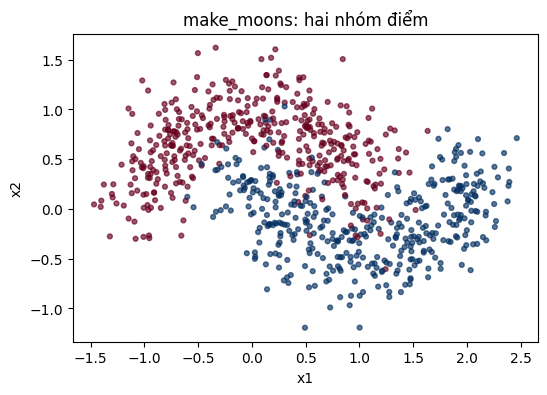

In [3]:
seed_everything(42)
X, y = make_moons(n_samples=800, noise=0.25, random_state=42)
ds = TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long))
tr, va = random_split(ds, [640, 160], generator=torch.Generator().manual_seed(42))
print(f"Train: {len(tr)}; validation: {len(va)}")
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu", s=12, alpha=0.65)
ax.set(title="make_moons: hai nhóm điểm", xlabel="x1", ylabel="x2")
plt.show()

## 3. Cấu hình so sánh

Hai tầng ẩn cùng độ rộng **8, 32, 64, 128** neuron, ReLU, LR=0.001.
Chỉ thay số neuron để đo ảnh hưởng của độ rộng.

In [4]:
configs = [Config(f'width{hidden}', hidden=(hidden, hidden)) for hidden in [8, 32, 64, 128]]

In [5]:
display(pd.DataFrame([asdict(config) for config in configs]))
print("Ví dụ mạng:")
print(build_mlp(configs[0].hidden, configs[0].activation, configs[0].dropout))

,name,hidden,activation,lr,dropout,weight_decay
0,width8,"(8, 8)",relu,0.001,0.0,0.0
1,width32,"(32, 32)",relu,0.001,0.0,0.0
2,width64,"(64, 64)",relu,0.001,0.0,0.0
3,width128,"(128, 128)",relu,0.001,0.0,0.0


Ví dụ mạng:
Sequential(
  (0): Linear(in_features=2, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=2, bias=True)
)


## 4. Huấn luyện

Mỗi batch: xóa gradient → dự đoán → tính loss → lan truyền ngược → cập nhật trọng số.
Sau mỗi epoch, đo train và validation ở chế độ `eval` để tắt Dropout.

Chạy đủ số epoch rồi báo cáo **mô hình cuối**, giữ cách làm đơn giản của mã mẫu.
Không chọn checkpoint sớm. Mọi cấu hình đều đặt lại seed 42 để so sánh công bằng.

In [6]:
def train_classifier(model, train_loader, val_loader, epochs=20, lr=1e-3, weight_decay=0.0):
    """Huấn luyện đủ số epoch và báo cáo mô hình cuối, không chọn checkpoint."""
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    train_eval_loader = DataLoader(train_loader.dataset, batch_size=128, shuffle=False)
    history = []
    start = perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        for X, y in train_loader:
            optimizer.zero_grad()
            logits = model(X)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
        train_metrics = evaluate(model, train_eval_loader)
        val_metrics = evaluate(model, val_loader)
        history.append({
            "epoch": epoch,
            **{f"train_{key}": value for key, value in train_metrics.items()},
            **{f"val_{key}": value for key, value in val_metrics.items()},
        })
    elapsed = perf_counter() - start
    return {
        **history[-1],
        "parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "seconds": elapsed,
    }, history

In [7]:
rows, histories, models = [], [], {}
for config in configs:
    seed_everything(42)
    model = build_mlp(config.hidden, config.activation, config.dropout)
    train_loader = DataLoader(
        tr, batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(42),
    )
    val_loader = DataLoader(va, batch_size=VAL_BATCH_SIZE, shuffle=False)
    metrics, trace = train_classifier(
        model, train_loader, val_loader, epochs=EPOCHS,
        lr=config.lr, weight_decay=config.weight_decay,
    )
    models[config.name] = model
    rows.append({**asdict(config), "hidden": "x".join(map(str, config.hidden)), **metrics})
    histories.extend({"config": config.name, **record} for record in trace)
    print(f"{config.name:20} loss={metrics['val_loss']:.4f} accuracy={metrics['val_accuracy']:.2%}")

width8               loss=0.3678 accuracy=84.38%


width32              loss=0.2343 accuracy=92.50%


width64              loss=0.1633 accuracy=94.38%


width128             loss=0.1724 accuracy=95.00%


## 5. Bảng kết quả và xuất file

Loss là cross-entropy trên validation, không cộng phạt trọng số. Accuracy là tỷ lệ đúng;
Macro-F1 coi các lớp quan trọng ngang nhau. Số tham số gồm trọng số và bias.
Thời gian gồm huấn luyện và đo train/validation, không gồm vẽ hình.
Accuracy/F1 ở thang [0, 1]. Chỉ có seed 42; không lấy trung bình nhiều lần chạy.

In [8]:
results, history = save_results(
    configs, tr, va, rows, histories, epochs=EPOCHS, models=models,
    val_batch_size=VAL_BATCH_SIZE, output_dir=OUTPUT_DIR, dataset='make_moons, n_samples=800, noise=0.25, random_state=42',
)
display(results[[
    "name", "hidden", "activation", "lr", "dropout", "weight_decay",
    "train_loss", "val_loss", "train_accuracy", "val_accuracy", "val_macro_f1", "parameters", "seconds",
]].style.format({
    "train_loss": "{:.4f}", "val_loss": "{:.4f}", "train_accuracy": "{:.4f}",
    "val_accuracy": "{:.4f}", "val_macro_f1": "{:.4f}", "seconds": "{:.2f}",
}).hide(axis="index"))

name,hidden,activation,lr,dropout,weight_decay,train_loss,val_loss,train_accuracy,val_accuracy,val_macro_f1,parameters,seconds
width8,8x8,relu,0.001000,0.000000,0.000000,0.3068,0.3678,0.8656,0.8438,0.8433,114,0.30
width32,32x32,relu,0.001000,0.000000,0.000000,0.1970,0.2343,0.9266,0.9250,0.9240,1218,0.30
width64,64x64,relu,0.001000,0.000000,0.000000,0.1414,0.1633,0.9484,0.9437,0.9426,4482,0.30
width128,128x128,relu,0.001000,0.000000,0.000000,0.1357,0.1724,0.9391,0.9500,0.9488,17154,0.33


## 6. Biểu đồ và learning curve

**Underfitting:** cả train và validation đều chưa tốt; cũng có thể do học chưa đủ epoch.
**Overfitting:** train tiếp tục tốt lên nhưng validation xấu đi.
Đọc xu hướng thực tế; không bắt buộc phải thấy overfitting chỉ sau 15/20 epoch.

### So sánh các điểm và ranh giới phân loại theo số neuron

Bốn hình dùng **cùng 800 điểm** với màu biểu diễn nhãn thật như hình dữ liệu ban đầu. Vùng nền là nhóm mô hình dự đoán; đường đen là ranh giới phân loại. Dấu × đánh dấu điểm validation dự đoán sai. So sánh độ cong của đường đen để thấy ảnh hưởng của 8, 32, 64 và 128 neuron mỗi tầng ẩn.

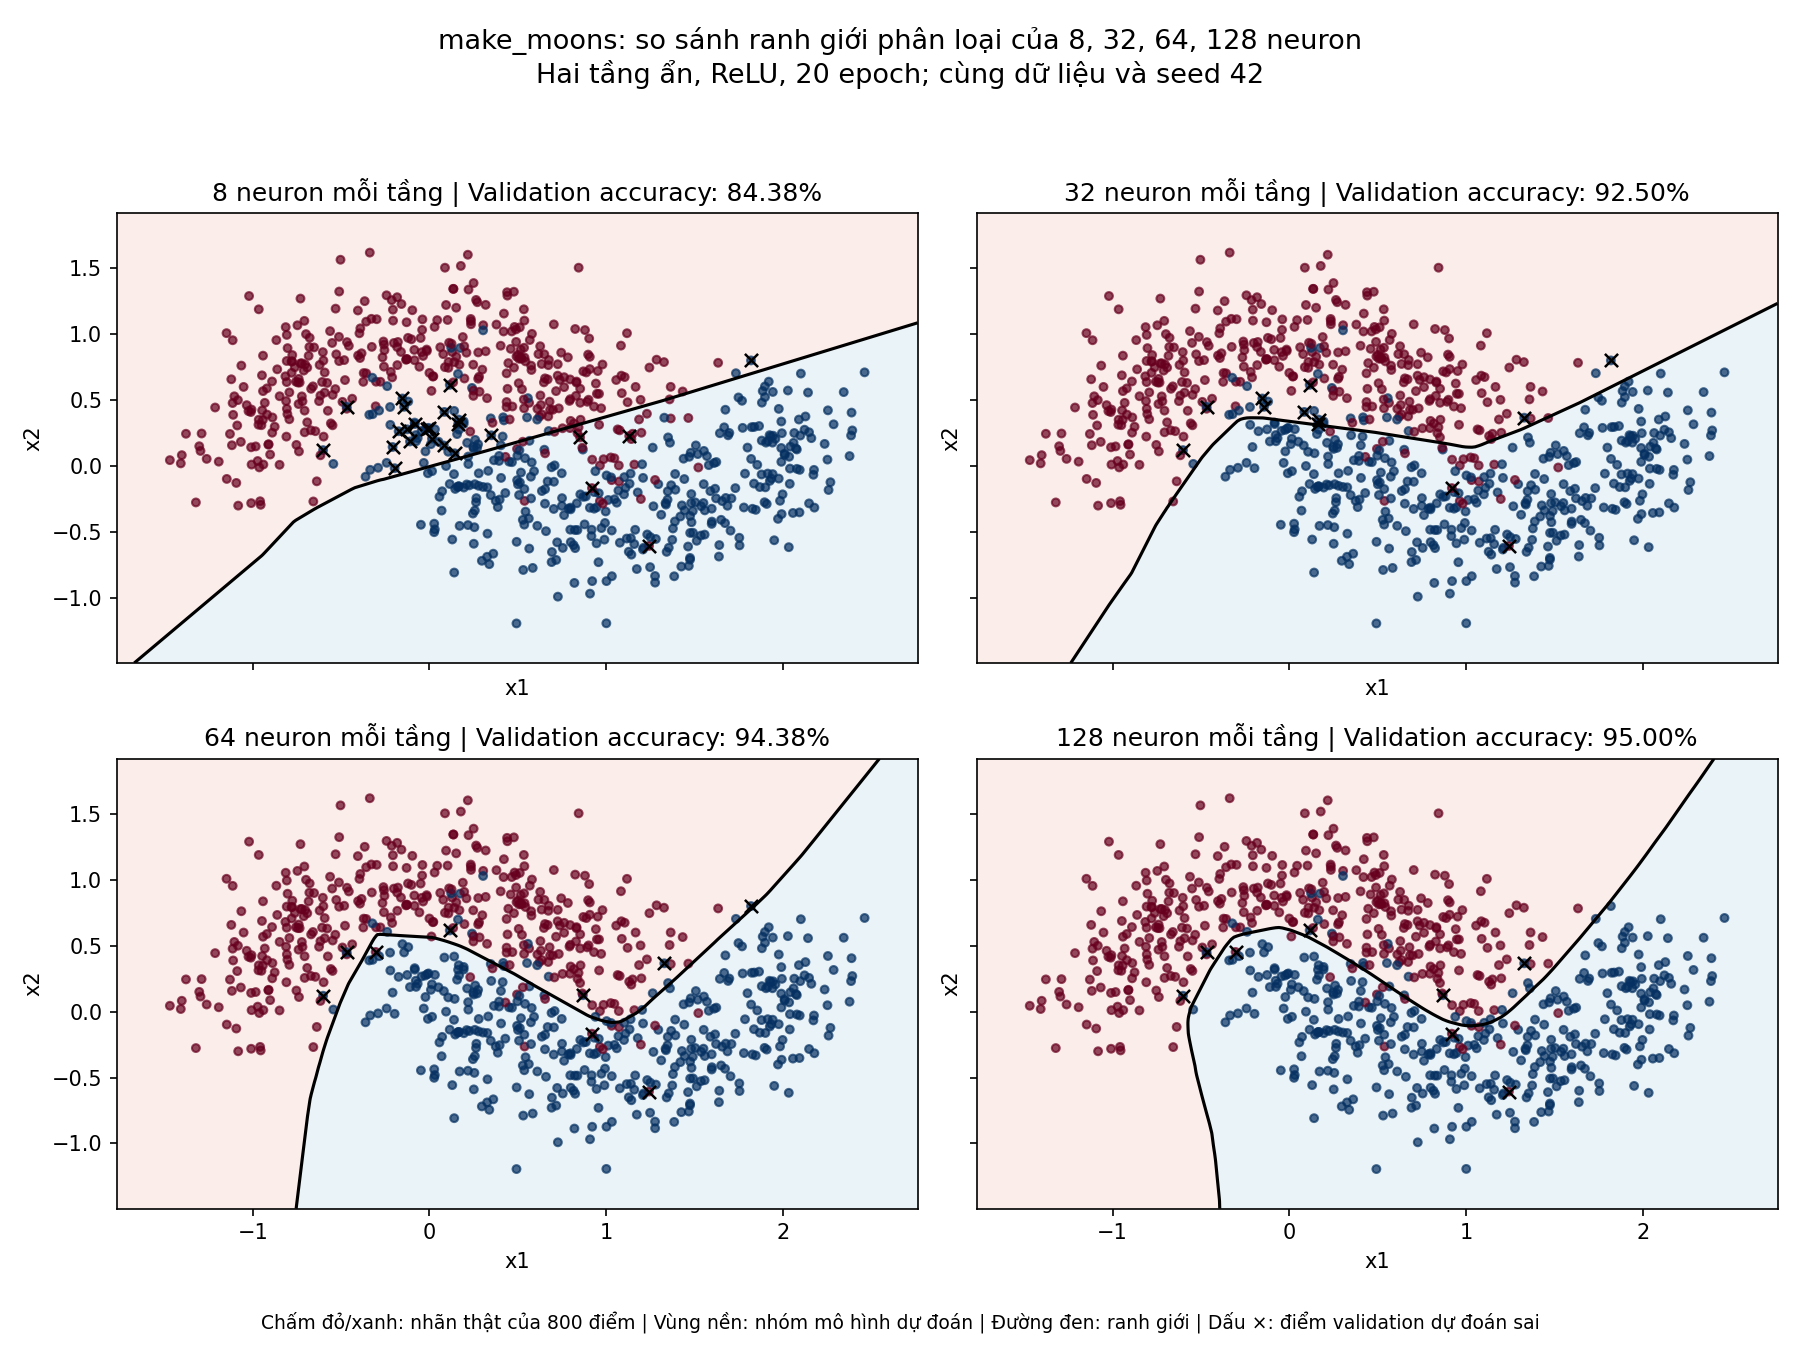

In [9]:
display(Image(filename=str(OUTPUT_DIR / "decision_boundaries.png")))

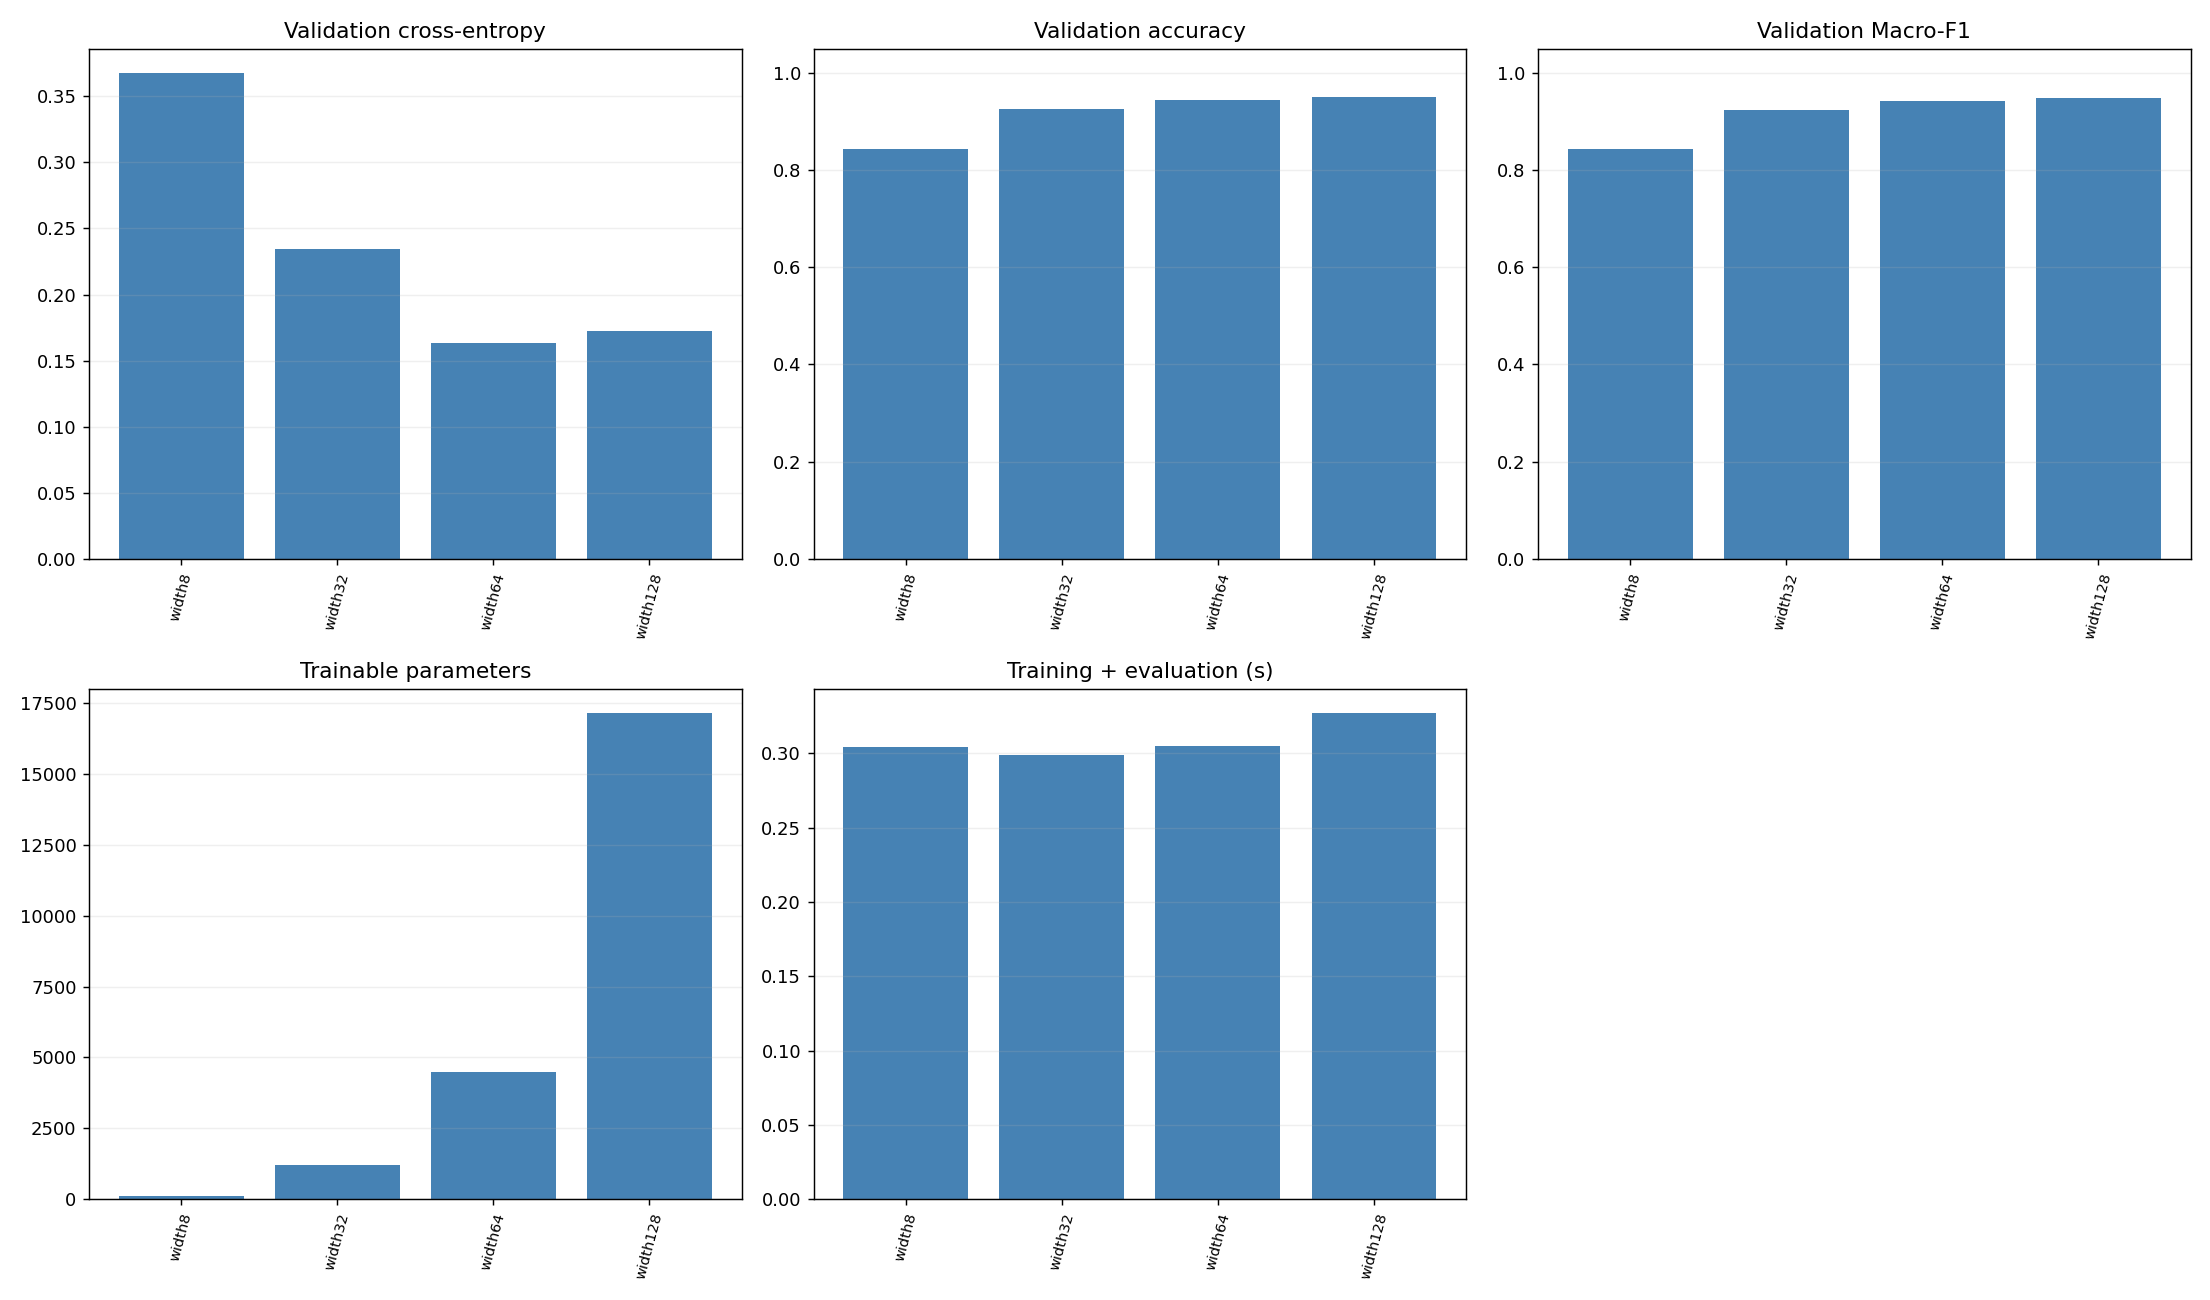

In [10]:
display(Image(filename=str(OUTPUT_DIR / "comparison.png")))

### So sánh trực tiếp 8, 32, 64 và 128 neuron

Mỗi mô hình có **hai tầng ẩn** với cùng độ rộng. Trục ngang là số neuron **mỗi tầng**, không phải tổng số neuron.

Ba biểu đồ trên so sánh Train/Validation tại epoch cuối; accuracy và Macro-F1 dùng thang [0, 1]. Hai biểu đồ dưới so sánh số tham số và thời gian. Góc dưới phải đặt đường validation loss của cả bốn mô hình trên cùng một hình.

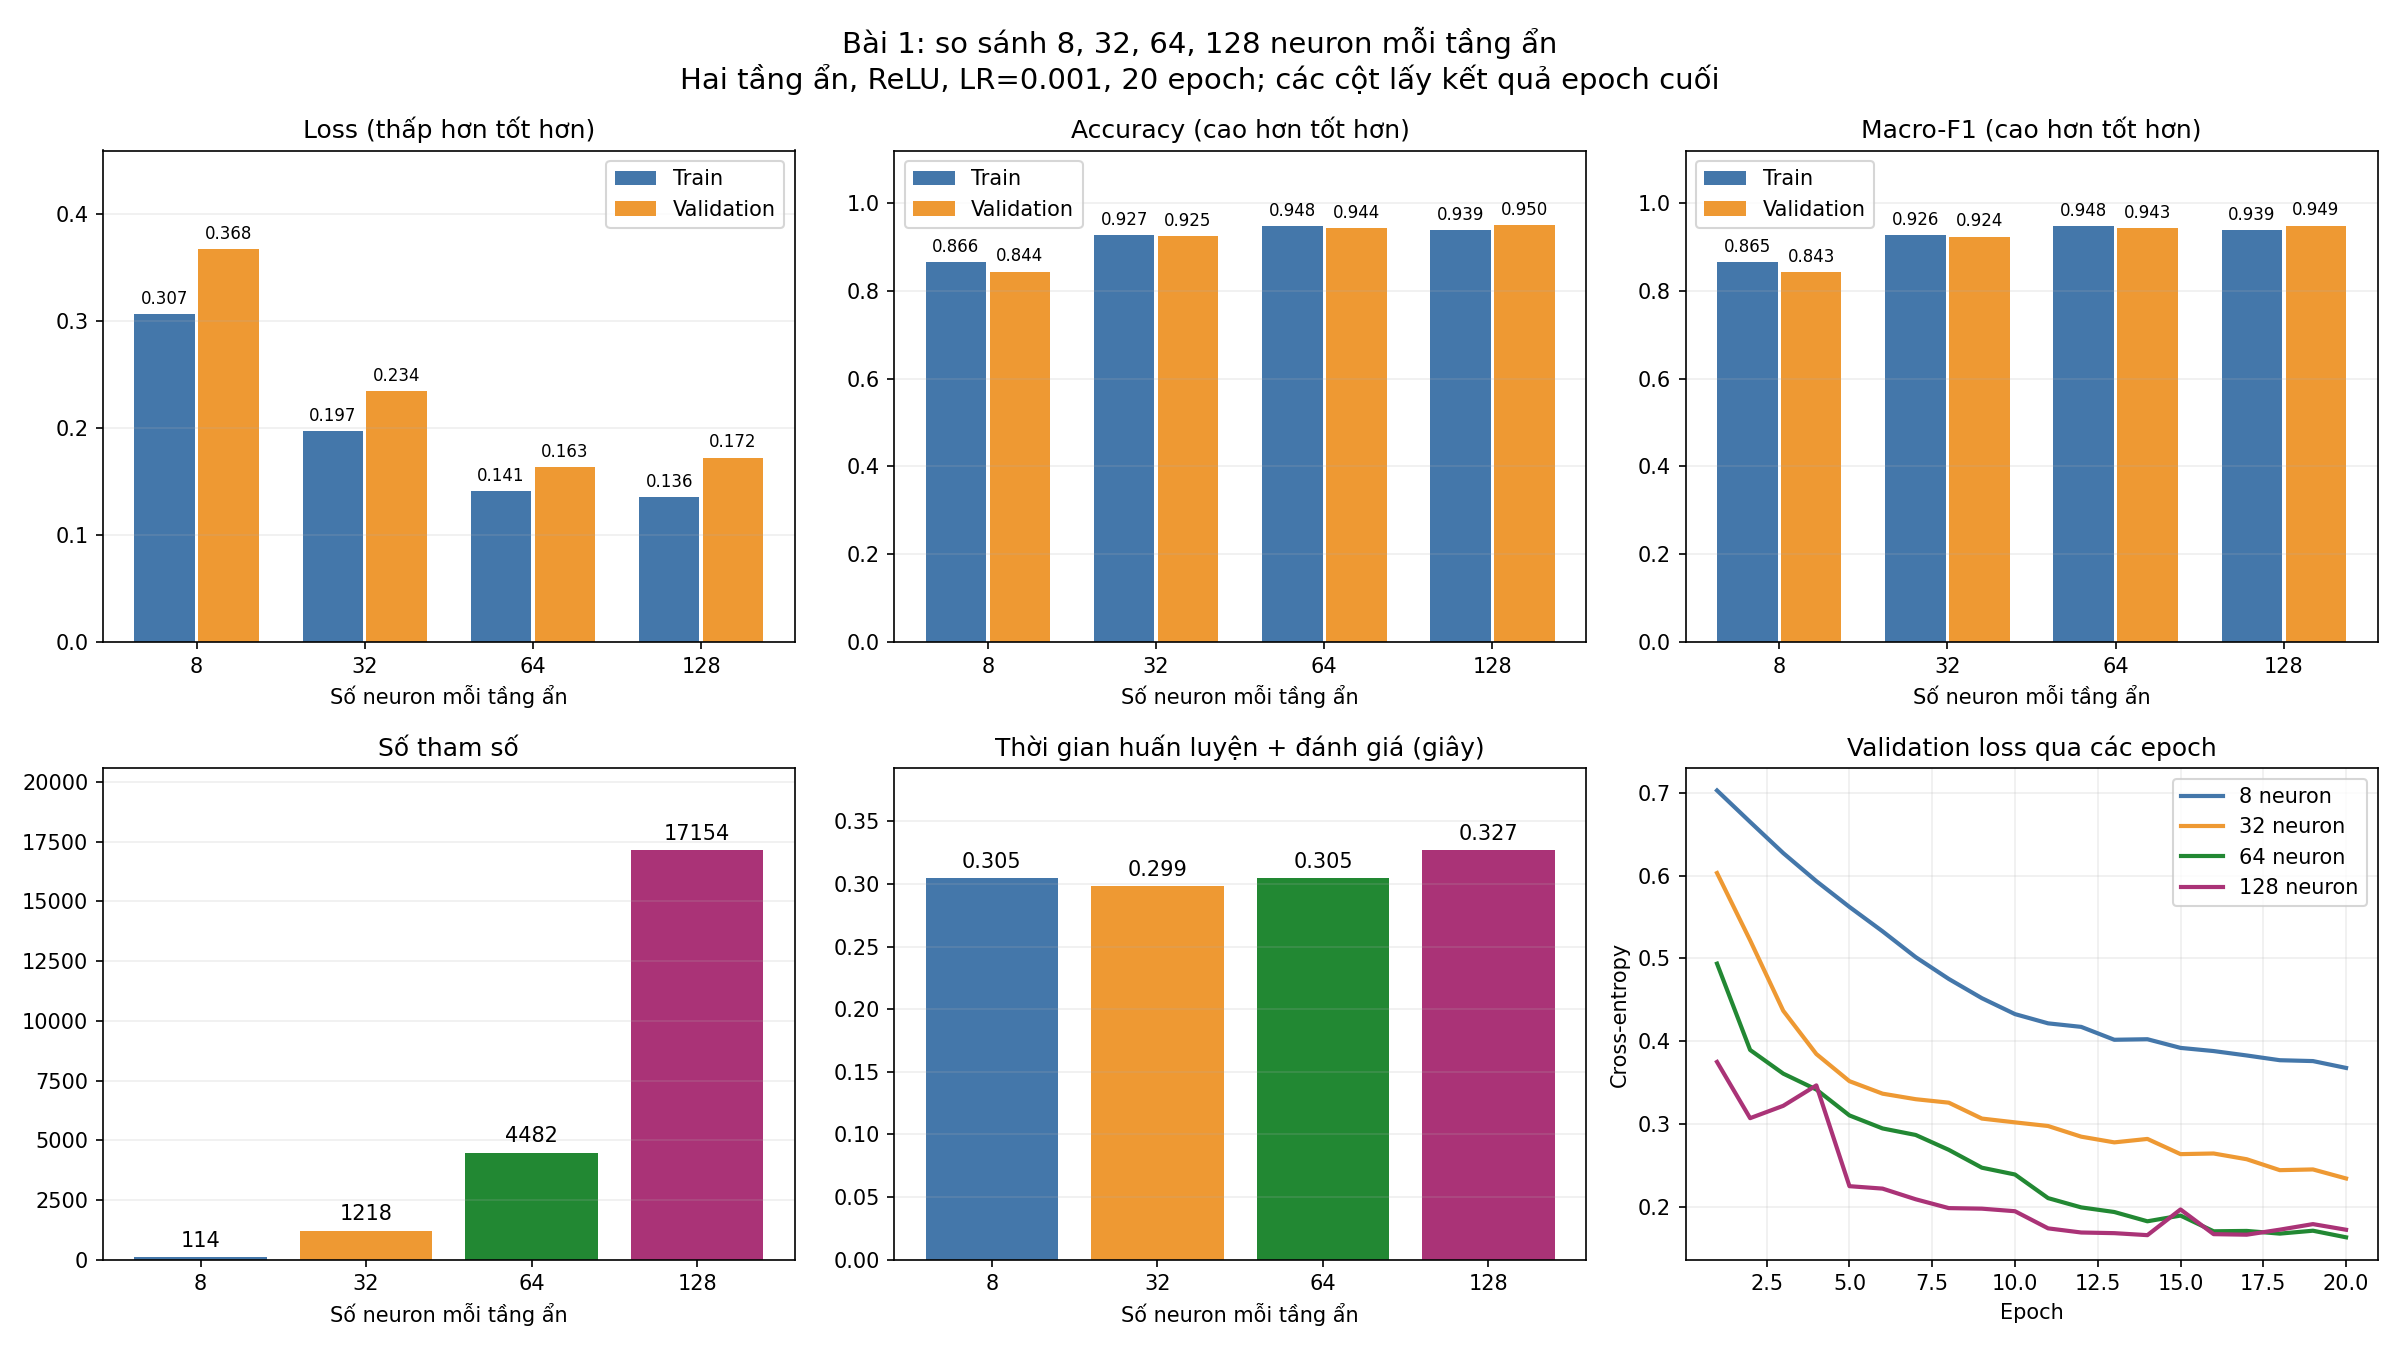

In [11]:
from common import save_width_comparison

# Dùng kết quả của lần chạy hiện tại, không huấn luyện thêm.
chart_path = save_width_comparison(results, history, OUTPUT_DIR)
display(Image(filename=str(chart_path)))

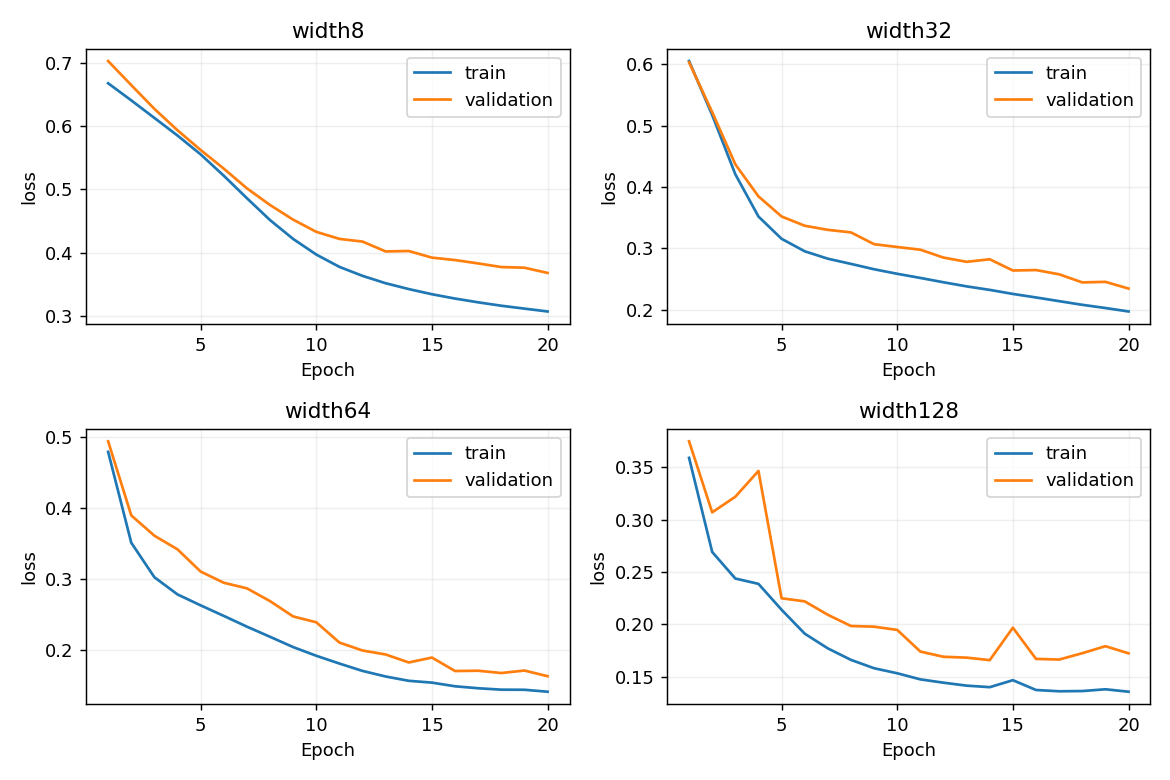

In [12]:
display(Image(filename=str(OUTPUT_DIR / "learning_loss.png")))

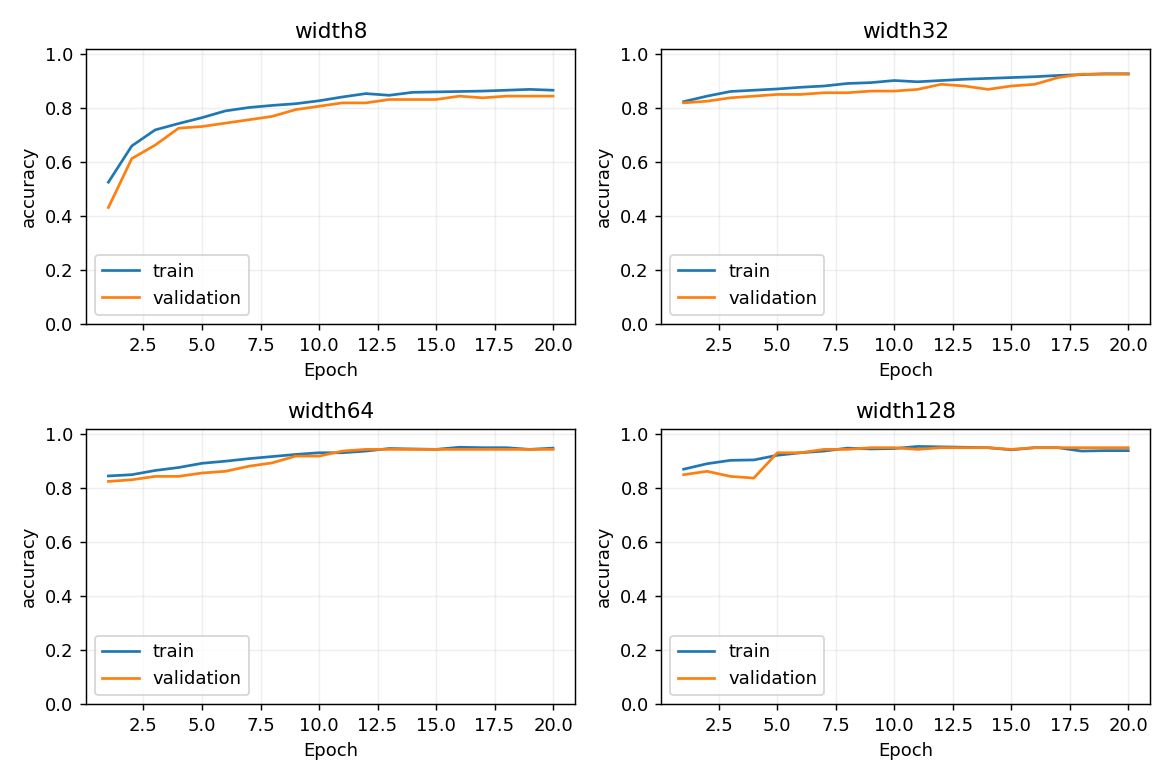

In [13]:
display(Image(filename=str(OUTPUT_DIR / "learning_accuracy.png")))

## 7. Nhận xét ngắn

Nhận xét tự cập nhật theo kết quả vừa chạy. Validation không phải test độc lập,
nên kết quả chỉ dùng cho bài khảo sát. Các ngưỡng nhận diện underfit/overfit là tham khảo.

In [14]:
report = (OUTPUT_DIR / "report.md").read_text(encoding="utf-8")
notes = report.split("## Nhận xét ngắn\n\n", 1)[1].split("\n## Biểu đồ", 1)[0]
display(Markdown(notes))

- Cấu hình có validation loss thấp nhất là **width64** (0.1633), accuracy 94.38%, Macro-F1 0.9426.
- Tăng 8 lên 128 neuron mỗi tầng làm tham số tăng từ 114 lên 17154; accuracy thay đổi từ 84.38% thành 95.00%. Mạng rộng có nhiều khả năng biểu diễn hơn nhưng cần nhiều phép tính; không bảo đảm accuracy tăng đều.
- Chưa thấy overfitting rõ theo tiêu chí train loss giảm thêm >0.005 nhưng val loss tăng >0.02 sau epoch có val loss thấp nhất; không nên ép kết luận overfitting khi đường học chưa thể hiện.
- Cả train/validation accuracy cuối đều dưới 90% ở **width8**: có dấu hiệu học chưa đủ tốt. Đây có thể là underfitting hoặc chưa hội tụ; nếu loss vẫn giảm thì 15/20 epoch có thể chưa đủ để kết luận thiếu năng lực mô hình.
- Chỉ chạy seed 42 để sát mã mẫu. Các ngưỡng chẩn đoán là tham khảo; cần đối chiếu learning curve. Không suy rộng kết quả cho mọi dữ liệu hoặc số epoch.
